# 01 Explore: PaySim mobile money transactions

**Project:** a fraud review queue for a South African mobile money provider.
**This notebook:** loads the data and documents every column (Step 2), then measures the imbalance, finds where fraud happens and checks for leakage (Step 3).

**Data:** PaySim, a simulated mobile money log built from one month of real transactions at a mobile money service in an African country. Lopez-Rojas, Elmir and Axelsson (2016), *PaySim: A financial mobile money simulator for fraud detection*. The generated dataset is published on [Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1) under CC BY-SA 4.0; this project downloads an identical copy from a [Hugging Face mirror](https://huggingface.co/datasets/purulalwani/Synthetic-Financial-Datasets-For-Fraud-Detection) because it needs no login.

## 1. Load the data

In [1]:
from pathlib import Path
import urllib.request
import pandas as pd
import numpy as np

RAW = Path("../data/raw/paysim.parquet")
URL = ("https://huggingface.co/datasets/purulalwani/Synthetic-Financial-Datasets-For-Fraud-Detection"
       "/resolve/main/financial_txns.parquet")

if not RAW.exists():
    print("Downloading PaySim (about 270 MB) ...")
    urllib.request.urlretrieve(URL, RAW)

tx = pd.read_parquet(RAW)
print(f"{len(tx):,} transactions, {tx.shape[1]} columns")
tx.head()

6,362,620 transactions, 11 columns


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
tx.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [3]:
tx.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
step,6362620.0,243.4,142.3,1.0,156.0,239.0,335.0,743.0
amount,6362620.0,179861.9,603858.2,0.0,13389.6,74871.9,208721.5,92445516.6
oldbalanceOrg,6362620.0,833883.1,2888242.7,0.0,0.0,14208.0,107315.2,59585040.4
newbalanceOrig,6362620.0,855113.7,2924048.5,0.0,0.0,0.0,144258.4,49585040.4
oldbalanceDest,6362620.0,1100701.7,3399180.1,0.0,0.0,132705.7,943036.7,356015889.4
newbalanceDest,6362620.0,1224996.4,3674128.9,0.0,0.0,214661.4,1111909.2,356179278.9
isFraud,6362620.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
isFlaggedFraud,6362620.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## 2. Checking what the columns mean

In [4]:
print("Transaction types:")
print(tx["type"].value_counts().to_string())
print(f"\nSteps run from {tx.step.min()} to {tx.step.max()} (one step = one hour, so {tx.step.max() / 24:.0f} days)")
print("\nFirst letter of account names:")
print("  origin:     ", tx.nameOrig.str[0].value_counts().to_dict())
print("  destination:", tx.nameDest.str[0].value_counts().to_dict())

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432

Steps run from 1 to 743 (one step = one hour, so 31 days)

First letter of account names:


  origin:      {'C': 6362620}


  destination: {'C': 4211125, 'M': 2151495}


In [5]:
merchant_dest = tx.nameDest.str.startswith("M")
print("Destination is a merchant (M...) for these types:", tx.loc[merchant_dest, "type"].unique().tolist())
print("Merchant destination balances are always zero:",
      bool((tx.loc[merchant_dest, ["oldbalanceDest", "newbalanceDest"]] == 0).all().all()))
print(f"\nisFlaggedFraud: {tx.isFlaggedFraud.sum()} transactions flagged by the provider's existing rule")

Destination is a merchant (M...) for these types: ['PAYMENT']


Merchant destination balances are always zero: True

isFlaggedFraud: 16 transactions flagged by the provider's existing rule


What this tells me for the data dictionary:

- `step` is the hour of the simulation (1 to 743, about 31 days). Hour of day and day number can be derived from it.
- Account names starting with **C** are customers, **M** are merchants. Merchants only receive `PAYMENT`s, and the simulator does not record merchant balances (always zero), so destination balances only mean something for customer-to-customer money.
- `isFlaggedFraud` is the provider's existing rule (it targets very large transfers). It fired only 16 times in a month, which is a useful "what the business does today" comparison in Step 4.
- `isFraud` is the label: the simulator marks transactions made by its fraudster agents, who take control of a customer's account and try to empty it by transferring the money out and cashing it out.

---
# Step 3: Imbalance, where fraud happens, and leakage

In [6]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

## 3. How rare is fraud?

In [7]:
n_fraud = int(tx.isFraud.sum())
print(f"Fraud: {n_fraud:,} of {len(tx):,} transactions = {tx.isFraud.mean():.3%}")
print(f"That is about 1 fraud in every {len(tx) // n_fraud:,} transactions.")
print(f"Predicting 'not fraud' for everything would be {1 - tx.isFraud.mean():.2%} accurate.")

Fraud: 8,213 of 6,362,620 transactions = 0.129%
That is about 1 fraud in every 774 transactions.
Predicting 'not fraud' for everything would be 99.87% accurate.


## 4. Which transaction types carry fraud?

In [8]:
by_type = tx.groupby("type").agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
by_type["fraud_rate"] = (by_type.fraud / by_type.transactions).round(5)
by_type.sort_values("fraud", ascending=False)

,transactions,fraud,fraud_rate
type,,,
CASH_OUT,2237500,4116,0.00184
TRANSFER,532909,4097,0.00769
CASH_IN,1399284,0,0.00000
DEBIT,41432,0,0.00000
PAYMENT,2151495,0,0.00000


Fraud happens **only** in `TRANSFER` and `CASH_OUT`, matching the fraud pattern in the simulator (move the money out, then cash it). `PAYMENT`, `CASH_IN` and `DEBIT` never contain fraud in this data, so the model only needs to score transfers and cash-outs. That removes 56% of the volume from the review problem straight away.

In [9]:
tc = tx[tx.type.isin(["TRANSFER", "CASH_OUT"])].copy()
tc["day"] = (tc.step - 1) // 24
tc["hour"] = (tc.step - 1) % 24
del tx
print(f"{len(tc):,} transfers and cash-outs, fraud rate {tc.isFraud.mean():.3%}")

2,770,409 transfers and cash-outs, fraud rate 0.296%


## 5. A problem with time: the simulation goes quiet

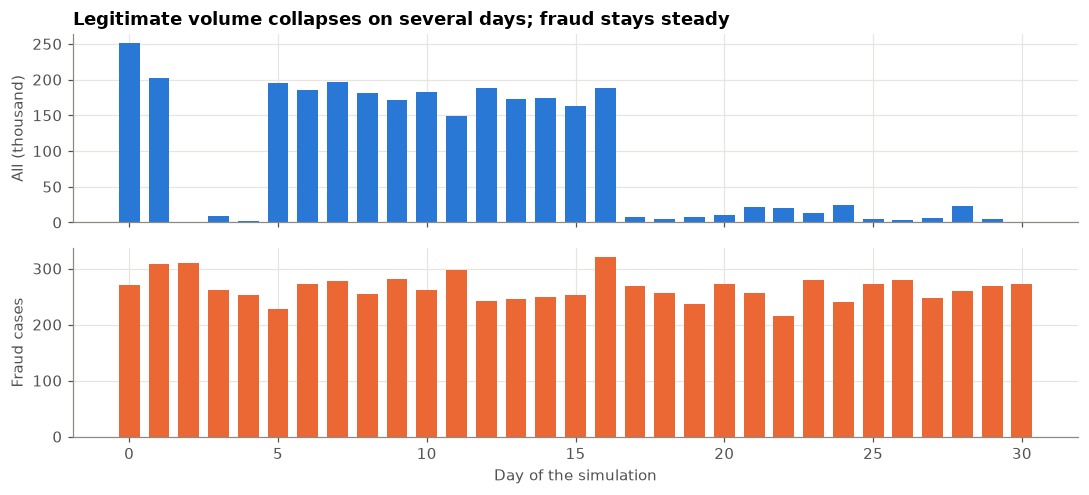

In [10]:
daily = tc.groupby("day").agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
ax1.bar(daily.index, daily.transactions / 1000, color=BLUE, width=0.7)
ax1.set_ylabel("All (thousand)")
ax1.set_title("Legitimate volume collapses on several days; fraud stays steady")
ax2.bar(daily.index, daily.fraud, color=ORANGE, width=0.7)
ax2.set_ylabel("Fraud cases")
ax2.set_xlabel("Day of the simulation")
fig.tight_layout()
fig.savefig("../figures/daily_volume.png")
plt.show()

Fraud is steady at about 250 to 300 a day for the whole month, but legitimate volume drops almost to zero on days 2 to 4 and from day 17 onwards. That is a feature of the simulator, not of real customer behaviour: on those days the "fraud rate" jumps to over 50%, which no real provider would see.

**Decision:** keep only the **14 days with normal volume** (more than 100,000 transfers and cash-outs). Training or testing on the quiet days would teach the model that fraud is common and make every result look better than it would be in practice.

In [11]:
normal_days = daily.index[daily.transactions > 100_000]
tc = tc[tc.day.isin(normal_days)].copy()
print(f"Normal-volume days kept: {list(normal_days)}")
print(f"{len(tc):,} transactions, {tc.isFraud.sum():,} fraud ({tc.isFraud.mean():.3%}), "
      f"about {len(tc) / len(normal_days):,.0f} transactions and {tc.isFraud.sum() / len(normal_days):.0f} frauds a day")

Normal-volume days kept: [0, 1, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
2,603,952 transactions, 3,765 fraud (0.145%), about 185,997 transactions and 269 frauds a day


## 6. When and how does fraud happen?

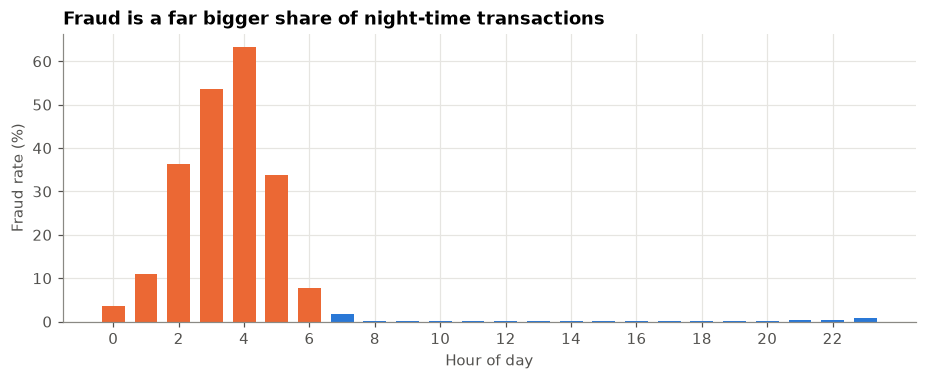

In [12]:
hourly = tc.groupby("hour").agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
hourly["fraud_rate"] = hourly.fraud / hourly.transactions
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(hourly.index, hourly.fraud_rate * 100, color=[ORANGE if h < 7 else BLUE for h in hourly.index], width=0.7)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Fraud rate (%)")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Fraud is a far bigger share of night-time transactions")
fig.savefig("../figures/fraud_rate_by_hour.png")
plt.show()

Fraudsters operate around the clock, but legitimate customers sleep. So between midnight and 6am a much larger share of transactions is fraud. Hour of day is known when a transaction happens, so it is a fair feature.

In [13]:
fraud, legit = tc[tc.isFraud == 1], tc[tc.isFraud == 0]
compare = pd.DataFrame({
    "median amount": [legit.amount.median(), fraud.amount.median()],
    "share TRANSFER": [(legit.type == "TRANSFER").mean(), (fraud.type == "TRANSFER").mean()],
    "amount equals full balance": [np.isclose(legit.amount, legit.oldbalanceOrg).mean(),
                                   np.isclose(fraud.amount, fraud.oldbalanceOrg).mean()],
    "receiver balance was zero": [(legit.oldbalanceDest == 0).mean(), (fraud.oldbalanceDest == 0).mean()],
}, index=["legitimate", "fraud"]).T
compare.round(3)

,legitimate,fraud
median amount,171352.770,412511.320
share TRANSFER,0.189,0.497
amount equals full balance,0.000,0.977
receiver balance was zero,0.138,0.647


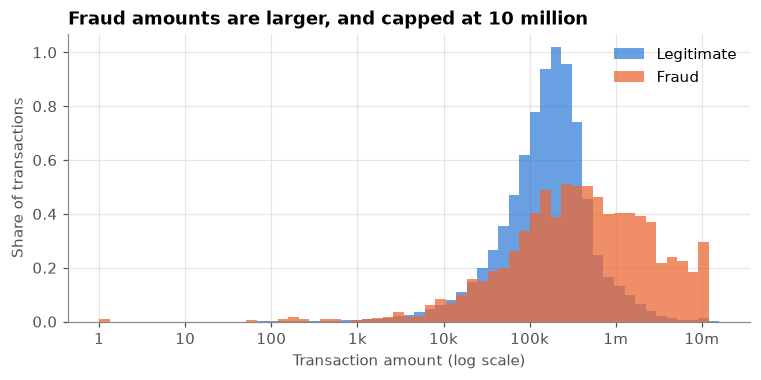

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 7.2, 60)
ax.hist(np.log10(legit.amount.clip(lower=1)), bins=bins, density=True, color=BLUE, alpha=0.7, label="Legitimate")
ax.hist(np.log10(fraud.amount.clip(lower=1)), bins=bins, density=True, color=ORANGE, alpha=0.75, label="Fraud")
ax.set_xticks(range(0, 8))
ax.set_xticklabels(["1", "10", "100", "1k", "10k", "100k", "1m", "10m"])
ax.set_xlabel("Transaction amount (log scale)")
ax.set_ylabel("Share of transactions")
ax.set_title("Fraud amounts are larger, and capped at 10 million")
ax.legend()
fig.savefig("../figures/amount_distribution.png")
plt.show()

**The fraud signature:** in 98% of fraud cases the amount equals the account's full balance: the fraudster empties the account in one go. Legitimate transactions in this data almost never do. That single pattern is so clean that it will make the models look very strong. Real fraud is much messier, which the README states plainly. Fraud amounts are also larger, and the simulator caps them at 10 million (large thefts are split into 10 million chunks).

## 7. Leakage check: anything that looks too good to be true?

Two kinds of balance column exist: **before** the transaction (`oldbalanceOrg`, `oldbalanceDest`) and **after** it (`newbalanceOrig`, `newbalanceDest`). A fraud check has to decide *before* the money moves, so only the "before" balances would be available in a real-time system. Let me see what the "after" columns would give away.

In [15]:
dest_frozen = (tc.oldbalanceDest == 0) & (tc.newbalanceDest == 0) & (tc.amount > 0)
print("Receiver's balance is zero both before and after receiving money:")
print(f"  fraud:      {dest_frozen[tc.isFraud == 1].mean():.1%}")
print(f"  legitimate: {dest_frozen[tc.isFraud == 0].mean():.3%}")

Receiver's balance is zero both before and after receiving money:
  fraud:      49.0%
  legitimate: 0.066%


Half of all frauds send money to an account whose balance is zero before **and after** receiving it, something that happens in under 0.1% of legitimate transactions. Money arriving without changing the balance is impossible in a real ledger; it is a recording quirk of the simulator. A model allowed to see the "after" balances would learn this quirk as a fraud rule, and that rule would not exist in production.

There is a second, more basic reason: a fraud check has to approve or block a transaction **before** it completes, so the balances after it are not yet known.

**Decision:** the model uses only information available at the moment of the transaction: type, amount, hour, and the balances **before** the transaction. `newbalanceOrig` and `newbalanceDest` are dropped.

## 8. Build the modelling table

In [16]:
model_df = pd.DataFrame({
    "day": tc.day, "hour": tc.hour,
    "is_transfer": (tc.type == "TRANSFER").astype(int),
    "amount": tc.amount,
    "log_amount": np.log1p(tc.amount),
    "log_balance_before": np.log1p(tc.oldbalanceOrg),
    "empties_account": np.isclose(tc.amount, tc.oldbalanceOrg).astype(int),
    "log_receiver_balance_before": np.log1p(tc.oldbalanceDest),
    "receiver_balance_zero": (tc.oldbalanceDest == 0).astype(int),
    "is_fraud": tc.isFraud,
})
model_df.to_parquet("../data/processed/transactions_model.parquet")
model_df.shape

(2603952, 10)

## 9. Findings

1. **Fraud is extremely rare:** 0.13% of all transactions, and 0.15% of transfers and cash-outs on normal days. Accuracy is meaningless here.
2. **Fraud has a clear shape:** only transfers and cash-outs, the full balance taken in one go, larger amounts, and a much higher share at night.
3. **The data has traps:** quiet days where fraud looks common, and "after" balances that leak the answer. Both are excluded before modelling.